# 03 · Forecasting: base models
Target: hourly BG day-ahead price of delivery day D, using only information available at gate closure on D-1. Expanding-window walk-forward (retrain monthly, test the next month); the last 3 months are a final holdout never used for tuning or model choices.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
R = ROOT / "reports"
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
ACC, BLUE, TEAL, RED, GREY = "#E08E0B", "#3F6FD8", "#1E9E92", "#D64545", "#7A8194"
pd.set_option("display.float_format", "{:,.2f}".format)
fg = json.loads((R / "feature_groups.json").read_text())
for g, cols in fg.items(): print(f"{g:18s} {len(cols):2d}  {cols[:6]}{' ...' if len(cols) > 6 else ''}")

calendar           10  ['hour', 'dow', 'month', 'is_weekend', 'is_holiday', 'is_bridge'] ...
price_lags         12  ['price_lag24', 'price_lag48', 'price_lag168', 'price_lag336', 'price_lag504', 'price_d1_mean'] ...
neighbours          9  ['price_RO_lag24', 'spread_BG_RO_lag24', 'price_RO_d1_mean', 'price_GR_lag24', 'spread_BG_GR_lag24', 'price_GR_d1_mean'] ...
system_forecasts    7  ['load_forecast', 'wind_forecast', 'solar_forecast', 'residual_load_forecast', 'res_load_ratio', 'res_load_d_mean'] ...
capacity            6  ['ntc_RO_to_BG', 'ntc_BG_to_RO', 'ntc_GR_to_BG', 'ntc_BG_to_GR', 'ntc_import_total', 'ntc_export_total']
flows               1  ['net_import_d2_mean']
weather            12  ['wfc_temp_sofia', 'wfc_wind100_sofia', 'wfc_rad_sofia', 'wfc_cloud_sofia', 'wfc_temp_dobrich', 'wfc_wind100_dobrich'] ...
fuels              11  ['fuel_brent_usd', 'fuel_brent_chg20', 'fuel_carbon_idx', 'fuel_carbon_chg20', 'fuel_gas_eur_mwh', 'fuel_gas_rel12'] ...


## Model comparison
Naive 1 = same hour yesterday, Naive 2 = same hour last week, Ridge, LightGBM (plus the ML-Plus models from notebook 04). Skill = 1 − MAE / MAE(best naive). DM = Diebold-Mariano test vs best naive.

In [2]:
cv = pd.read_csv(R / "metrics_cv.csv"); ho = pd.read_csv(R / "metrics_holdout.csv")
print("Walk-forward CV months"); display(cv.set_index("model").round(3))
print("Final holdout (last 3 months)"); display(ho.set_index("model").round(3))

Walk-forward CV months


,MAE,RMSE,MAE_fold_mean,MAE_fold_std,n_folds,skill_vs_best_naive,MAE_spike_hours,MAE_negative_hours,DM_stat,DM_p,significant_5pct
model,,,,,,,,,,,
naive_d1,28.95,49.86,28.95,7.60,25,0.00,75.65,20.42,NaN,NaN,NaN
naive_w1,32.86,57.82,32.83,10.88,25,-0.14,86.75,31.58,3.72,0.00,False
ridge,24.16,39.94,24.16,6.75,25,0.17,60.87,19.82,-9.09,0.00,True
lightgbm,22.84,41.04,22.85,6.94,25,0.21,65.23,16.31,-10.16,0.00,True
lightgbm_capacity,23.15,41.32,23.15,6.86,25,0.20,65.34,17.29,-9.48,0.00,True
lightgbm_fuels,23.11,41.16,23.11,6.78,25,0.20,64.89,17.62,-9.55,0.00,True
lightgbm_level,23.68,41.08,23.68,7.70,25,0.18,64.60,16.99,-8.75,0.00,True
mlp,23.55,41.10,23.54,6.54,25,0.19,65.79,17.87,-8.82,0.00,True
ensemble,22.32,39.60,22.32,6.54,25,0.23,63.14,16.37,-11.63,0.00,True


Final holdout (last 3 months)


,MAE,RMSE,MAE_fold_mean,MAE_fold_std,n_folds,skill_vs_best_naive,MAE_spike_hours,MAE_negative_hours,DM_stat,DM_p,significant_5pct
model,,,,,,,,,,,
naive_d1,30.84,43.48,30.86,2.92,3,0.00,28.71,37.98,NaN,NaN,NaN
naive_w1,39.96,52.76,39.92,10.55,3,-0.30,39.35,30.36,2.62,0.01,False
ridge,27.93,36.02,27.93,6.82,3,0.09,28.79,26.63,-1.81,0.07,False
lightgbm,30.02,39.45,29.99,9.91,3,0.03,33.85,16.20,-0.32,0.75,False
lightgbm_capacity,29.76,39.80,29.73,9.89,3,0.04,33.43,18.31,-0.40,0.69,False
lightgbm_fuels,31.80,41.95,31.77,11.68,3,-0.03,37.13,15.53,0.30,0.76,False
lightgbm_level,26.39,35.96,26.40,6.24,3,0.14,27.63,35.67,-2.72,0.01,True
mlp,40.32,49.32,40.28,16.03,3,-0.31,47.92,28.76,2.45,0.02,False
ensemble,31.13,39.82,31.11,10.50,3,-0.01,35.00,21.53,0.12,0.91,False


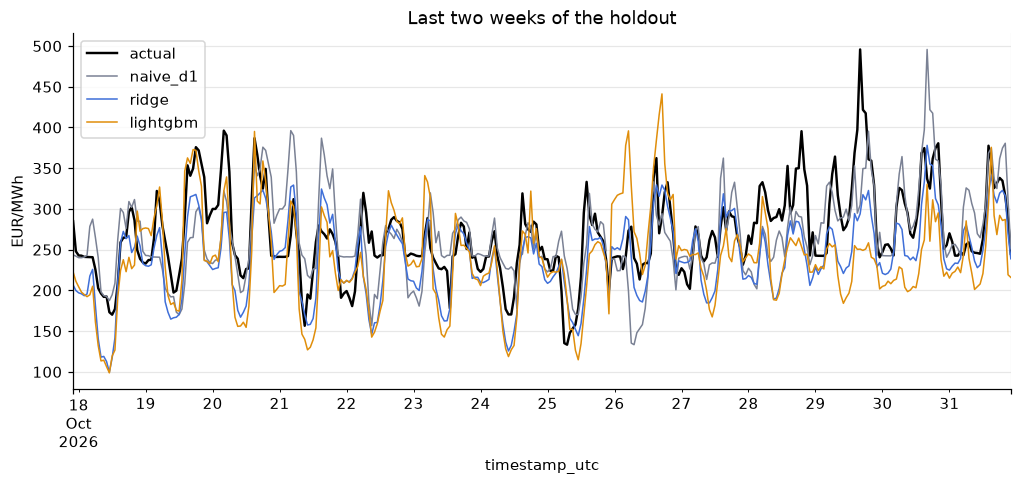

In [3]:
pr = pd.read_csv(R / "predictions.csv", parse_dates=["delivery_day"])
pr["timestamp_utc"] = pd.to_datetime(pr.timestamp_utc, utc=True)
wk = pr[pr.delivery_day >= pr.delivery_day.max() - pd.Timedelta(days=13)].set_index("timestamp_utc")
ax = wk.actual.plot(color="k", lw=1.6, label="actual")
for m, c in [("naive_d1", GREY), ("ridge", BLUE), ("lightgbm", ACC)]: wk[m].plot(ax=ax, color=c, lw=1, label=m)
ax.legend(); ax.set_ylabel("EUR/MWh"); ax.set_title("Last two weeks of the holdout"); plt.show()

## Where does it fail?

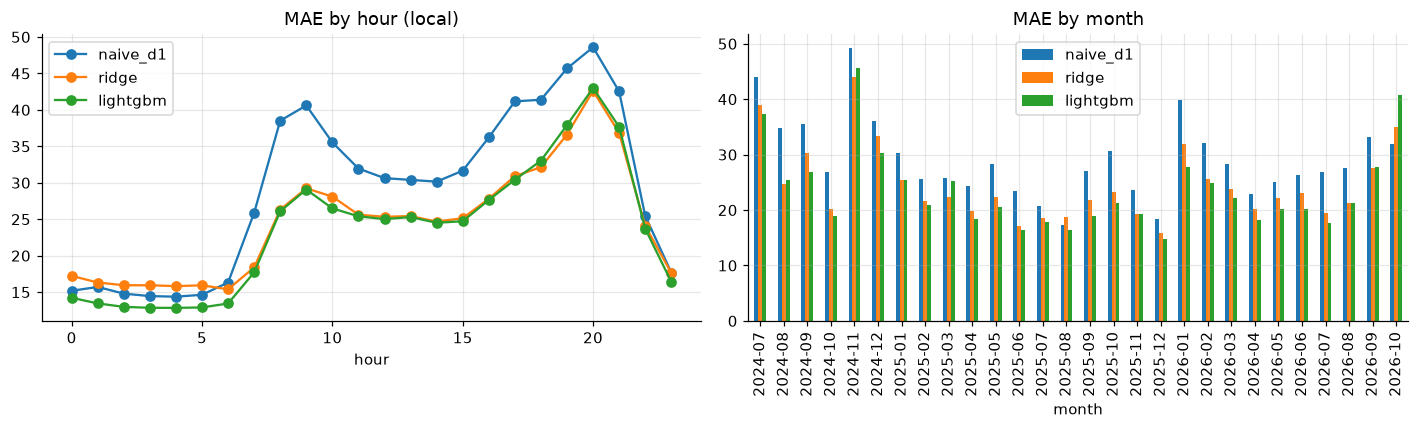

                    MAE  MAE_spike_hours  MAE_negative_hours
model                                                       
naive_d1          28.90            75.60               20.40
naive_w1          32.90            86.80               31.60
ridge             24.20            60.90               19.80
lightgbm          22.80            65.20               16.30
lightgbm_capacity 23.20            65.30               17.30
lightgbm_fuels    23.10            64.90               17.60
lightgbm_level    23.70            64.60               17.00
mlp               23.50            65.80               17.90
ensemble          22.30            63.10               16.40


In [4]:
eh = pd.read_csv(R / "error_by_hour.csv", index_col=0); em = pd.read_csv(R / "error_by_month.csv", index_col=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
eh[["naive_d1", "ridge", "lightgbm"]].plot(ax=ax[0], marker="o", title="MAE by hour (local)")
em[["naive_d1", "ridge", "lightgbm"]].plot.bar(ax=ax[1], title="MAE by month"); plt.tight_layout(); plt.show()
print(cv.set_index("model")[["MAE", "MAE_spike_hours", "MAE_negative_hours"]].round(1))

In [5]:
h_ = ho.set_index("model"); best_naive = h_.loc[h_.index.str.startswith("naive"), "MAE"].idxmin()
lg = h_.loc["lightgbm"]; rd = h_.loc["ridge"]
print(f"Holdout: best naive = {best_naive} (MAE {h_.loc[best_naive, 'MAE']:.2f}); Ridge MAE {rd.MAE:.2f} "
      f"(skill {rd.skill_vs_best_naive:+.1%}); LightGBM MAE {lg.MAE:.2f} (skill {lg.skill_vs_best_naive:+.1%}, "
      f"DM p = {lg.DM_p:.3g}).")

Holdout: best naive = naive_d1 (MAE 30.84); Ridge MAE 27.93 (skill +9.4%); LightGBM MAE 30.02 (skill +2.7%, DM p = 0.748).


**Honest conclusion.** The model beats the naive baselines clearly in normal hours, but its error is several times larger in spike and negative-price hours, and largest in the evening ramp. The missing drivers are known: plant outages (REMIT), hydro reservoir levels and interconnector capacities are not in the data, and fuel/carbon prices (monthly gas, daily TTF, Brent, a carbon proxy) were tested in `src/fuel_experiment.py` and did not improve the forecast. The model is a fundamentals-plus-persistence model, not an oracle.